In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "data_labeling").is_dir():
    ROOT = ROOT.parent

path = ROOT / "data_labeling/data_labels/sciquality/labels_sciquality_2010_2026_binary.csv"

labels = pd.read_csv(path)
labels["year"] = labels["label"].str[:4].astype(int)

print("Total images:", len(labels))
labels.head()

Total images: 128117


,label,goes_class,year
0,2010/12/06/HMI.m2010.12.06_07.00.00.jpg,0,2010
1,2010/12/06/HMI.m2010.12.06_08.00.00.jpg,0,2010
2,2010/12/06/HMI.m2010.12.06_09.00.00.jpg,0,2010
3,2010/12/06/HMI.m2010.12.06_10.00.00.jpg,0,2010
4,2010/12/06/HMI.m2010.12.06_11.00.00.jpg,0,2010


In [3]:
counts = labels["goes_class"].value_counts().sort_index()
counts.index = ["NF", "FL"]

summary = pd.DataFrame({
    "images": counts,
    "percentage": 100 * counts / counts.sum(),
})

summary.round(2)

,images,percentage
NF,98318,76.74
FL,29799,23.26


In [4]:
yearly = pd.crosstab(labels["year"], labels["goes_class"])
yearly.columns = ["NF", "FL"]
yearly["total"] = yearly["NF"] + yearly["FL"]
yearly["FL_percent"] = 100 * yearly["FL"] / yearly["total"]

yearly.round(2)

,NF,FL,total,FL_percent
year,,,,
2010,562,0,562,0.00
2011,4933,1595,6528,24.43
2012,4897,1619,6516,24.85
2013,5697,1959,7656,25.59
2014,4883,3522,8405,41.90
2015,6276,2235,8511,26.26
2016,7936,401,8337,4.81
2017,7927,450,8377,5.37
2018,8393,24,8417,0.29


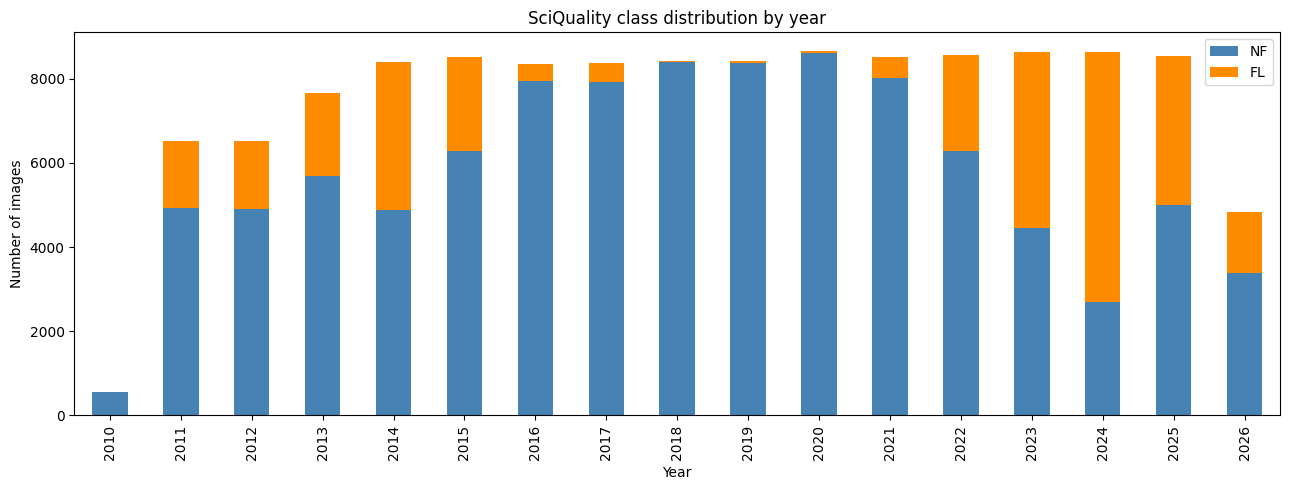

In [5]:
yearly[["NF", "FL"]].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 5),
    color=["steelblue", "darkorange"],
)

plt.title("SciQuality class distribution by year")
plt.xlabel("Year")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

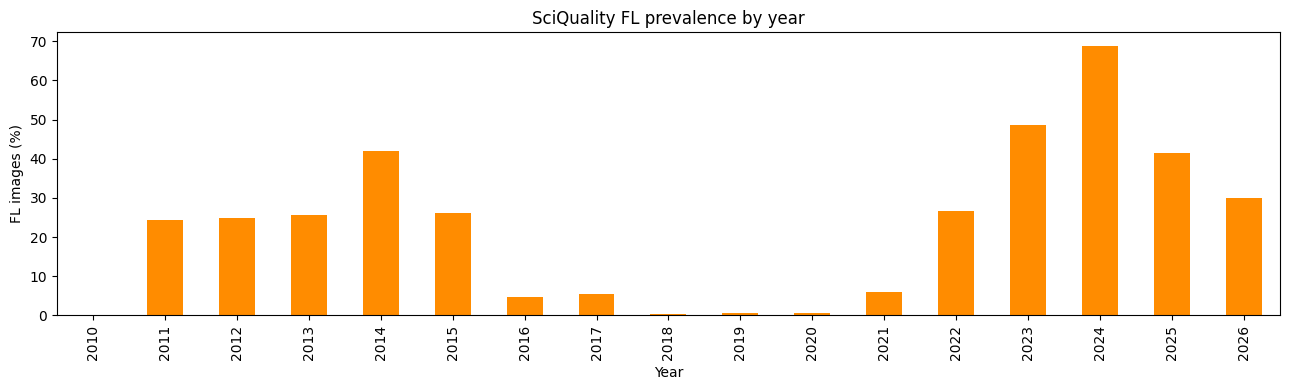

In [6]:
yearly["FL_percent"].plot(
    kind="bar",
    figsize=(13, 4),
    color="darkorange",
)

plt.title("SciQuality FL prevalence by year")
plt.xlabel("Year")
plt.ylabel("FL images (%)")
plt.tight_layout()
plt.show()